# 16장 · 도구 요청을 실행하고 결과를 모델에 돌려주기

15장에서 받은 주말 운영 시간 요청에 실제 조회 결과를 붙입니다. 하나의 호출 요청, 프로그램이 실행한 함수, 모델에 돌려줄 결과를 같은 call_id로 따라가 봅시다.

실행을 확인한 커널은 Python 3.12.15입니다.

Python 3 커널을 선택하고 위에서부터 실행하세요. 과제 셀에 직접 코드를 작성한 뒤 바로 아래에서 풀이를 펼쳐 보세요.

## 요청을 받은 쪽에서 실제 함수 실행하기

명세만 본 모델은 운영 시간을 알 수 없습니다. 읽기 전용 조회 함수 안의 표에서 시간을 꺼내면 비로소 답에 쓸 값이 생깁니다.


### 셀 01 · 가상 도서관 조회

이번 셀에서는 모델 없이 파이썬 함수를 직접 부릅니다.

In [1]:
def get_library_hours(day):
    hours = {"weekday": "09:00~18:00", "weekend": "10:00~16:00"}
    return {"day": day, "hours": hours[day], "source": "수업용 가상 도서관"}

print(get_library_hours("weekend")["hours"])

10:00~16:00


10:00~16:00은 주말 표에서 꺼낸 값입니다. 이 함수는 실제 도서관에 접속하지 않습니다. 허용되지 않은 인자가 들어오는지는 함수를 부르기 전에 검사합니다.

### 셀 02 · 호출 요청을 실행 결과로 바꾸기

제공 함수는 요청의 이름과 인자를 검사합니다. 성공했을 때 어떤 값이 output 안에 담기는지 읽으세요.

이번 노트북은 주말 조회 요청을 새로 만들어 call_1이라는 ID를 붙입니다. 15장의 예제 ID는 call_demo_1이었습니다. 이제부터 이 요청에 답하는 결과는 call_1을 그대로 사용해야 합니다.

In [2]:
import json

def execute_call(item):
    if not isinstance(item.get("call_id"), str) or not item["call_id"].strip():
        raise ValueError("call_id 없음 또는 공백: 결과 연결 불가")
    try:
        if item.get("name") != "get_library_hours":
            raise ValueError("허용하지 않은 도구")
        args = json.loads(item["arguments"])
        if not isinstance(args, dict) or set(args) != {"day"}:
            raise ValueError("인자 필드 불일치")
        if args["day"] not in {"weekday", "weekend"}:
            raise ValueError("지원하지 않는 요일 값")
        result = {"ok": True, "data": get_library_hours(args["day"])}
    except (ValueError, TypeError, KeyError):
        result = {"ok": False, "error": "invalid_tool_request"}
    return {"type": "function_call_output", "call_id": item["call_id"],
            "output": json.dumps(result, ensure_ascii=False)}

call = {"type": "function_call", "call_id": "call_1", "name": "get_library_hours", "arguments": '{"day":"weekend"}'}
reply = execute_call(call)
print(json.loads(reply["output"])["data"]["hours"])

10:00~16:00


같은 10:00~16:00이 나오지만 이번 값은 reply의 output에 담긴 JSON 문자열에서 읽었습니다. 모델에 보낼 항목의 type은 function_call_output입니다.

## 결과를 어느 요청에 붙일지 확인하기

결과를 돌려주는 쪽은 임의의 새 ID를 붙이지 않습니다. 모델이 보낸 호출 항목의 call_id를 그대로 써야 요청과 결과가 한 쌍이 됩니다.

<!-- motion:matching-stubs -->
**도구 결과는 어느 요청의 영수증일까요?**

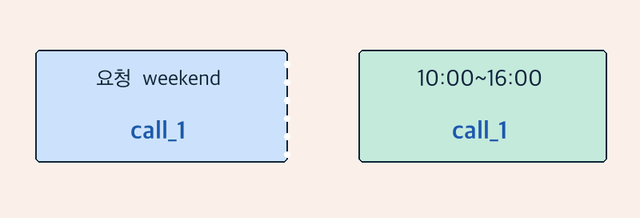

요청과 결과에 같은 call_id가 남습니다. 주말 시간 10:00~16:00을 읽을 때도 이 표식으로 원래 요청을 찾습니다.
<!-- /motion -->


### 과제 03 · 호출 ID 연결 확인

원본 call과 결과 reply의 ID가 같은지 확인하고, 같으면 그 ID를 출력하세요.

In [3]:
# 두 ID가 같은지 검사하세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>assert reply[&quot;call_id&quot;] == call[&quot;call_id&quot;]
print(reply[&quot;call_id&quot;])</code></pre>
<p>실행 결과</p><pre><code>call_1</code></pre>
<p>call_1입니다. 모델에게 다음 답변을 요청할 때는 사용자 질문과 호출 항목 다음에 이 결과를 넣습니다.</p>
</details>

### 셀 04 · 잘못 들어온 요일

이번 요청의 ID는 유효하나 day가 명세의 두 선택지 밖에 있습니다.

In [4]:
bad = {**call, "arguments": '{"day":"Friday"}'}
rejected = execute_call(bad)
print(json.loads(rejected["output"]))

{'ok': False, 'error': 'invalid_tool_request'}


ok가 False이고 error가 invalid_tool_request입니다. 허용되지 않은 요일로 얻은 시간을 사용자에게 보여 주는 일을 막았습니다.

## 모델이 읽을 마지막 기록 만들기

도구 호출을 제안한 응답과 함수 실행 결과를 대화 끝에 차례로 넣습니다. 모델에 다시 보내기 직전에는 결과가 어느 항목인지, 조회 실패를 개관 시간으로 오해하지 않았는지 살펴보세요.

### 호출 요청 한 건이 답변에 쓰이기까지

**주말 운영 시간을 요청합니다.**　이 시점에는 조회할 함수와 요일만 정해졌습니다.

```
call_id = call_1
get_library_hours(day="weekend")
```

**시간표에서 주말 항목을 찾습니다.**　함수를 호출한 프로그램이 결과를 받았습니다. 요청을 받기만 한 상태에서는 이 값을 알 수 없습니다.

```
hours = 10:00~16:00
```

**조회 결과에 같은 ID를 붙입니다.**　function_call_output과 원래 요청이 call_1로 이어집니다. 대화 목록에서 서로 이웃하는지만 보고 연결하면 호출 두 개의 결과가 뒤바뀔 수 있습니다.

```
type = function_call_output
call_id = call_1
운영 시간 = 10:00~16:00
```

**결과에서 시간을 읽어 안내합니다.**　이 장의 풀이에서는 저장한 결과로 안내 문장을 만듭니다.

```
가상 주말 운영 시간: 10:00~16:00
```


### 셀 05 · 대화에 결과 더하기

대화 내역을 만든 뒤 마지막 항목의 유형을 읽습니다.

In [5]:
history = [{"role": "user", "content": "주말 운영 시간은?"}]
history.append(call)
history.append(reply)
print(history[-1]["type"])

function_call_output


function_call_output이 나옵니다. 모델의 최종 메시지는 아직 없습니다. 다음 과제에서는 조회 값으로 안내 문장을 직접 만듭니다.

### 과제 06 · 결과에서 최종 안내 만들기

현재 대화의 마지막 항목을 읽어 성공한 결과일 때만 시간을 넣어 안내하세요. 이 문장은 실제 모델 답변 대신 쓰는 연습용 문구입니다.

In [6]:
# history에서 성공 여부와 시간을 읽으세요.

<details><summary>정답 코드와 실행 결과 보기</summary>
<pre><code>payload = json.loads(history[-1][&quot;output&quot;])
if payload[&quot;ok&quot;]:
    print(&quot;가상 주말 운영 시간:&quot;, payload[&quot;data&quot;][&quot;hours&quot;])
else:
    print(&quot;운영 시간을 확인하지 못했습니다.&quot;)</code></pre>
<p>실행 결과</p><pre><code>가상 주말 운영 시간: 10:00~16:00</code></pre>
<p>예제에서는 ‘가상 주말 운영 시간: 10:00~16:00’이 나옵니다. 한 번의 왕복에서 도구 실행은 한 번이고, 실제 SDK를 쓰는 구성이라면 최초 요청과 최종 답 요청을 따로 셉니다.</p>
</details>

## 돌아보기

요청 ID, 도구 반환값, 사용자에게 보여 줄 문장 중 하나가 비어 있는 대화를 상상해 보세요. 어느 단계에서 멈춰야 하는지 설명할 수 있으면 다음 장의 여러 번 왕복도 한 번씩 읽을 수 있습니다.

### 실행하기 전에 걸러지는 요청

**함수 이름·인자 제안**　호출 ID와 함께 도구를 요청합니다.

```
function_call
```

**허용 목록·필드 확인**　조건이 틀리면 오류 결과를 만듭니다.

```
weekday 또는 weekend → 조회로 이동
그 밖의 값 → 검사 실패, 조회 0회
```

**가상 운영 시간 조회**　읽기 전용 딕셔너리를 조회합니다.

```
hours
```

**동일 ID로 결과 전달**　도구 결과를 받은 뒤 최종 답변을 요청합니다.

```
function_call_output
```
